# Probe set overlap: Visium vs Chromium Flex

SIMPlex hybridizes two whole-transcriptome probe sets on the same section (Visium CytAssist, then Chromium Flex).
Do they target the same sites, and does Flex after Visium show gene-specific depletion?

1. Which probe set each SpaceRanger / CellRanger run used (from `web_summary.html` under `data/`).
2. Sequence overlap between the published 10x probe sets.
3. Per-gene overlap for mouse (Visium v1.0 vs Flex v1.0.1).
4. Pseudobulk gene correlation Visium vs Flex on matched sections; outlier genes.

Outputs: `figs/technical/probe_overlap/`

In [1]:
import re
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import scanpy as sc
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.R").exists())
PROBE_DIR = ROOT / "data/other/external_references/probe_sets"
OUT_DIR = ROOT / "figs/technical/probe_overlap"
PROBE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

URL = "https://cf.10xgenomics.com/supp/"
PROBE_SETS = {
    "Visium Human v1.0":     "spatial-exp/probeset/Visium_Human_Transcriptome_Probe_Set_v1.0_GRCh38-2020-A.csv",
    "Visium Human v2.0":     "spatial-exp/probeset/Visium_Human_Transcriptome_Probe_Set_v2.0_GRCh38-2020-A.csv",
    "Chromium Human v1.0.1": "cell-exp/probeset/Chromium_Human_Transcriptome_Probe_Set_v1.0.1_GRCh38-2020-A.csv",
    "Chromium Human v1.1.0": "cell-exp/probeset/Chromium_Human_Transcriptome_Probe_Set_v1.1.0_GRCh38-2024-A.csv",
    "Visium Mouse v1.0":     "spatial-exp/probeset/Visium_Mouse_Transcriptome_Probe_Set_v1.0_mm10-2020-A.csv",
    "Visium Mouse v2.0":     "spatial-exp/probeset/Visium_Mouse_Transcriptome_Probe_Set_v2.0_mm10-2020-A.csv",
    "Chromium Mouse v1.0.1": "cell-exp/probeset/Chromium_Mouse_Transcriptome_Probe_Set_v1.0.1_mm10-2020-A.csv",
}

## 1. Probe set versions used

Empty if SpaceRanger / CellRanger outputs are not unpacked under `data/`.

In [2]:
def pipeline_info(html):
    txt = html.read_text(errors="ignore")
    get = lambda key: (m := re.search(rf'\["{key}",\s*"([^"]*)"', txt)) and m.group(1)
    return {"run": str(html.parent.relative_to(ROOT / "data")), "probe_set": get("Probe Set Name"),
            "pipeline": get("Pipeline Version"), "chemistry": get("Chemistry")}

runs = pd.DataFrame([pipeline_info(f) for f in sorted(ROOT.glob("data/**/web_summary.html"))])
runs if len(runs) else "No web_summary.html under data/ (unpack the Zenodo deposit first)"

,run,probe_set,pipeline,chemistry
0,single_nuclei/cellranger/breast_cancer/55um/pa...,Chromium Human Transcriptome Probe Set v1.0.1,None,Fixed RNA Profiling
1,single_nuclei/cellranger/breast_cancer/55um/pa...,Chromium Human Transcriptome Probe Set v1.0.1,None,Fixed RNA Profiling
2,single_nuclei/cellranger/breast_cancer/55um/pa...,Chromium Human Transcriptome Probe Set v1.0.1,None,Fixed RNA Profiling
3,single_nuclei/cellranger/breast_cancer/55um/pa...,Chromium Human Transcriptome Probe Set v1.0.1,None,Fixed RNA Profiling
4,single_nuclei/cellranger/breast_cancer/55um/pa...,Chromium Human Transcriptome Probe Set v1.0.1,None,Fixed RNA Profiling
5,single_nuclei/cellranger/breast_cancer/55um/pa...,Chromium Human Transcriptome Probe Set v1.0.1,None,Fixed RNA Profiling
6,single_nuclei/cellranger/breast_cancer/55um/pa...,Chromium Human Transcriptome Probe Set v1.0.1,None,Fixed RNA Profiling
7,single_nuclei/cellranger/breast_cancer/55um/pa...,Chromium Human Transcriptome Probe Set v1.0.1,None,Fixed RNA Profiling
8,single_nuclei/cellranger/breast_cancer/55um/pa...,Chromium Human Transcriptome Probe Set v1.0.1,None,Fixed RNA Profiling
9,single_nuclei/cellranger/breast_cancer/55um/pa...,Chromium Human Transcriptome Probe Set v1.0.1,None,Fixed RNA Profiling


## 2. Load probe sets (downloaded from 10x if missing)

In [3]:
def load(name):
    f = PROBE_DIR / Path(PROBE_SETS[name]).name
    if not f.exists():
        urlretrieve(URL + PROBE_SETS[name], f)
    return pd.read_csv(f, comment="#")

probes = {name: load(name) for name in PROBE_SETS}

pd.DataFrame({name: {"probes": len(p),
                     "probes included": p.included.sum(),
                     "genes included": p.gene_id[p.included].nunique()}
              for name, p in probes.items()}).T

,probes,probes included,genes included
Visium Human v1.0,20259,19008,18308
Visium Human v2.0,54580,53504,18085
Chromium Human v1.0.1,54580,53444,18082
Chromium Human v1.1.0,54580,53459,18129
Visium Mouse v1.0,21178,20057,19758
Visium Mouse v2.0,55538,55187,19059
Chromium Mouse v1.0.1,55538,55128,19059


SpaceRanger 2.0.1 reports the mouse panel without a version. The features in the matrix identify it:
every gene in the mouse Visium matrices is in Visium Mouse **v1.0**, ~1,100 are absent from v2.0.

In [4]:
mb = sc.read_10x_h5(ROOT / "data/spatial/spaceranger/mouse_brain/B/filtered_feature_bc_matrix.h5")
pd.Series({n: len(set(mb.var.gene_ids) - set(probes[n].gene_id)) for n in PROBE_SETS if "Mouse" in n},
          name="MB genes not in panel")

/srv/home/m.abreumachado/apps/miniconda3/lib/python3.13/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Visium Mouse v1.0           0
Visium Mouse v2.0        1113
Chromium Mouse v1.0.1    1113
Name: MB genes not in panel, dtype: int64

## 3. Sequence overlap between all panels

Cell = shared probe sequences as % of the union of both panels.

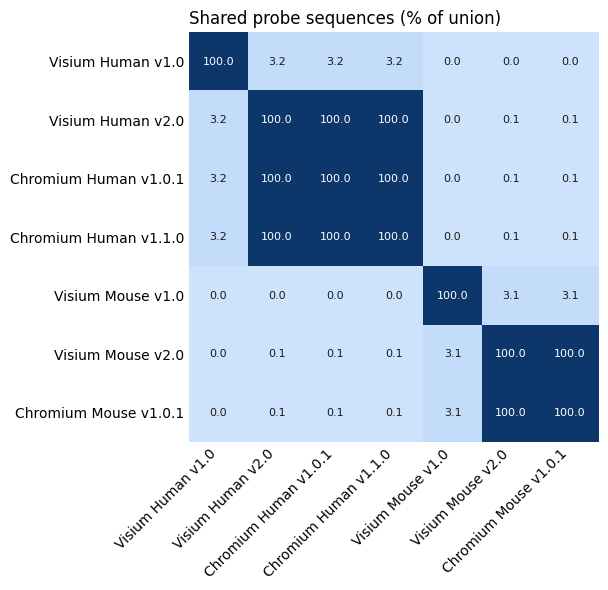

In [5]:
names = list(probes)
seqs = {n: set(probes[n].probe_seq) for n in names}
overlap = pd.DataFrame([[100 * len(seqs[a] & seqs[b]) / len(seqs[a] | seqs[b]) for b in names] for a in names],
                       index=names, columns=names)
overlap.round(1).to_csv(OUT_DIR / "sequence_overlap_pct.csv")

blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(overlap, cmap=blues, vmin=0, vmax=100)
for i in range(len(names)):
    for j in range(len(names)):
        v = overlap.iat[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white" if v > 50 else "#1a1a1a")
ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
ax.set_yticks(range(len(names)), names)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Shared probe sequences (% of union)", loc="left")
fig.tight_layout()
fig.savefig(OUT_DIR / "sequence_overlap_heatmap.pdf")
plt.show()

## 4. Visium v2.0 vs Chromium Flex v1.0.1

Same sequences — what differs? Probes matched by sequence, compared on probe ID and `included`.

In [6]:
for species in ["Human", "Mouse"]:
    v, c = probes[f"Visium {species} v2.0"], probes[f"Chromium {species} v1.0.1"]
    m = v.merge(c, on="probe_seq", suffixes=("_visium", "_flex"))
    diff = m[(m.probe_id_visium != m.probe_id_flex) | (m.included_visium != m.included_flex)]
    genes_v, genes_c = set(v.gene_id[v.included]), set(c.gene_id[c.included])
    only_v = v[v.gene_id.isin(genes_v - genes_c)].probe_id.str.split("|").str[1].unique()
    print(f"{species}: {len(m)} shared sequences, {len(diff)} with different ID/flag "
          f"({diff.probe_id_flex.str.startswith('DEPRECATED_').sum()} marked DEPRECATED_ in Flex)")
    print(f"  genes measured: {len(genes_v & genes_c)} both, Visium only {sorted(only_v)}, "
          f"Flex only {len(genes_c - genes_v)}")
    diff.to_csv(OUT_DIR / f"differing_probes_{species.lower()}.csv", index=False)

Human: 54580 shared sequences, 61 with different ID/flag (61 marked DEPRECATED_ in Flex)
  genes measured: 18082 both, Visium only ['GABARAPL2', 'SLC39A4', 'TKT'], Flex only 0
Mouse: 55538 shared sequences, 59 with different ID/flag (59 marked DEPRECATED_ in Flex)
  genes measured: 19059 both, Visium only [], Flex only 0


## 5. Mouse: does Flex bind the same site as Visium?

Each gene has 1–3 Flex probes. A Flex probe binds the **same site** as Visium if its sequence is identical to a Visium v1.0 probe.

- **same site**: all Flex probes of the gene bind a Visium site
- **mixed**: some do, some don't
- **different site**: no Flex probe binds a Visium site (these sites are not cut by RNase H)

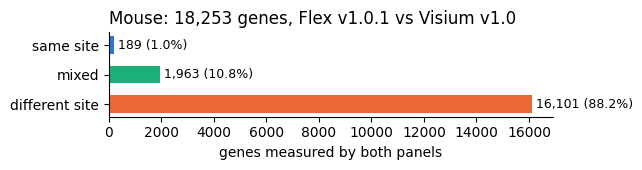

In [7]:
panel = {s: set(probes[v].gene_id[probes[v].included]) & set(probes[f].gene_id[probes[f].included])
         for s, v, f in [("Human", "Visium Human v2.0", "Chromium Human v1.0.1"),
                         ("Mouse", "Visium Mouse v1.0", "Chromium Mouse v1.0.1")]}
symbol = pd.concat(probes.values()).query("included").drop_duplicates("gene_id").set_index("gene_id").probe_id.str.split("|").str[1]

fx = probes["Chromium Mouse v1.0.1"].query("included")
frac = fx.probe_seq.isin(set(probes["Visium Mouse v1.0"].probe_seq)).groupby(fx.gene_id).mean()
frac = frac[frac.index.isin(panel["Mouse"])]
n_flex = fx.groupby("gene_id").size()
category = pd.Series(np.select([frac == 1, frac > 0], ["same site", "mixed"], "different site"), index=frac.index, name="category")
category.rename_axis("gene_id").to_frame().assign(symbol=symbol, frac_shared=frac, n_flex_probes=n_flex).to_csv(OUT_DIR / "mouse_gene_overlap_category.csv")

CAT_COL = {"same site": "#2a78d6", "mixed": "#1baf7a", "different site": "#eb6834"}
n = category.value_counts().reindex(CAT_COL)
fig, ax = plt.subplots(figsize=(6.5, 1.8))
ax.barh(n.index, n, color=list(CAT_COL.values()), height=0.6)
for y, v in enumerate(n):
    ax.text(v, y, f" {v:,} ({100 * v / n.sum():.1f}%)", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("genes measured by both panels")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Mouse: {n.sum():,} genes, Flex v1.0.1 vs Visium v1.0", loc="left")
fig.tight_layout()
fig.savefig(OUT_DIR / "mouse_gene_overlap_category.pdf")
plt.show()

## 6. Gene correlation Visium vs Flex (same section)

Pseudobulk per gene: counts summed over all spots (Visium, SpaceRanger filtered matrix) and all nuclei
(Flex, CellRanger `sample_filtered`, libraries of the same sample summed). Genes included in both panels,
matched on Ensembl ID, then CPM and log1p. patient3 (low quality, not in the paper) is excluded. Mouse snRNA `sn_sample_2` (MB_2) is from section B; section A
(adjacent, spatial-only) shown for reference.

In [8]:
SR, CR = ROOT / "data/spatial/spaceranger", ROOT / "data/single_nuclei/cellranger"
PAIRS = {f"patient{i}": (f"breast_cancer/55um/patient{i}_55um", f"breast_cancer/55um/patient{i}") for i in (1, 2, 4, 5, 6, 7, 8, 9)}  # patient3: low quality, not in paper
PAIRS |= {f"patient10_{k}": (f"breast_cancer/55um/patient10_55um/patient10_{k}", f"breast_cancer/55um/patient10/patient10_{k}")
          for k in (1, 2)}
PAIRS |= {"MB B": ("mouse_brain/B", "mouse_brain/sn_sample_2"), "MB A": ("mouse_brain/A", "mouse_brain/sn_sample_2")}

def pseudobulk(d, name):
    files = sorted(d.glob(f"**/{name}"))
    assert files, d
    return sum(pd.Series(np.asarray(a.X.sum(0)).ravel(), index=a.var.gene_ids)
               for a in map(sc.read_10x_h5, files)), len(files)

expr, rows = {}, []
for s, (sp, sn) in PAIRS.items():
    (v, nv), (f, nf) = pseudobulk(SR / sp, "filtered_feature_bc_matrix.h5"), pseudobulk(CR / sn, "sample_filtered_feature_bc_matrix.h5")
    genes = sorted(panel["Mouse" if s.startswith("MB") else "Human"] & set(v.index) & set(f.index))
    df = pd.DataFrame({"visium": v[genes], "flex": f[genes]})
    expr[s] = df = np.log1p(df / df.sum() * 1e6)
    rows.append({"sample": s, "flex_libraries": nf, "genes": len(df),
                 "pearson": stats.pearsonr(df.visium, df.flex)[0], "spearman": stats.spearmanr(df.visium, df.flex)[0]})
cor = pd.DataFrame(rows).set_index("sample")
cor.round(3).to_csv(OUT_DIR / "visium_flex_correlation.csv")
cor.round(3)

/srv/home/m.abreumachado/apps/miniconda3/lib/python3.13/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


/srv/home/m.abreumachado/apps/miniconda3/lib/python3.13/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


/srv/home/m.abreumachado/apps/miniconda3/lib/python3.13/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


/srv/home/m.abreumachado/apps/miniconda3/lib/python3.13/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


/srv/home/m.abreumachado/apps/miniconda3/lib/python3.13/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


...

/srv/home/m.abreumachado/apps/miniconda3/lib/python3.13/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


/srv/home/m.abreumachado/apps/miniconda3/lib/python3.13/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


/srv/home/m.abreumachado/apps/miniconda3/lib/python3.13/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


/srv/home/m.abreumachado/apps/miniconda3/lib/python3.13/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


,flex_libraries,genes,pearson,spearman
sample,,,,
patient1,1,18082,0.942,0.948
patient2,1,18082,0.950,0.956
patient4,2,18082,0.882,0.902
patient5,2,18082,0.922,0.933
patient6,2,18082,0.949,0.948
patient7,1,18082,0.808,0.840
patient8,1,18082,0.854,0.871
patient9,1,18082,0.857,0.874
patient10_1,1,18082,0.951,0.945


## 7. Outlier genes

Linear fit of Flex on Visium (log1p CPM) over genes detected in both; outlier = |z| of the residual > 3.
Positive z: higher in Flex (nuclei) than Visium (whole tissue); negative: lower in Flex.
Human probes are sequence-identical between panels, so human outliers are not due to probe design.

In [9]:
def residual_z(df):
    d = df[(df > 0).all(axis=1)].copy()
    slope, icpt = np.polyfit(d.visium, d.flex, 1)
    r = d.flex - (slope * d.visium + icpt)
    d["z"] = (r - r.mean()) / r.std()
    return d

res = {s: residual_z(df) for s, df in expr.items()}
out = pd.concat([d[d.z.abs() > 3].assign(sample=s) for s, d in res.items()]).rename_axis("gene_id").reset_index()
out["symbol"] = out.gene_id.map(symbol)
out["category"] = out.gene_id.map(category).where(out["sample"].str.startswith("MB"))
out.sort_values(["sample", "z"]).to_csv(OUT_DIR / "visium_flex_outlier_genes.csv", index=False)
cor["outliers_up"] = out[out.z > 0].groupby("sample").size()
cor["outliers_down"] = out[out.z < 0].groupby("sample").size()
cor.fillna(0).round(3)

,flex_libraries,genes,pearson,spearman,outliers_up,outliers_down
sample,,,,,,
patient1,1,18082,0.942,0.948,56,130
patient2,1,18082,0.950,0.956,76,104
patient4,2,18082,0.882,0.902,72,138
patient5,2,18082,0.922,0.933,74,93
patient6,2,18082,0.949,0.948,116,93
patient7,1,18082,0.808,0.840,88,128
patient8,1,18082,0.854,0.871,101,109
patient9,1,18082,0.857,0.874,85,120
patient10_1,1,18082,0.951,0.945,92,35


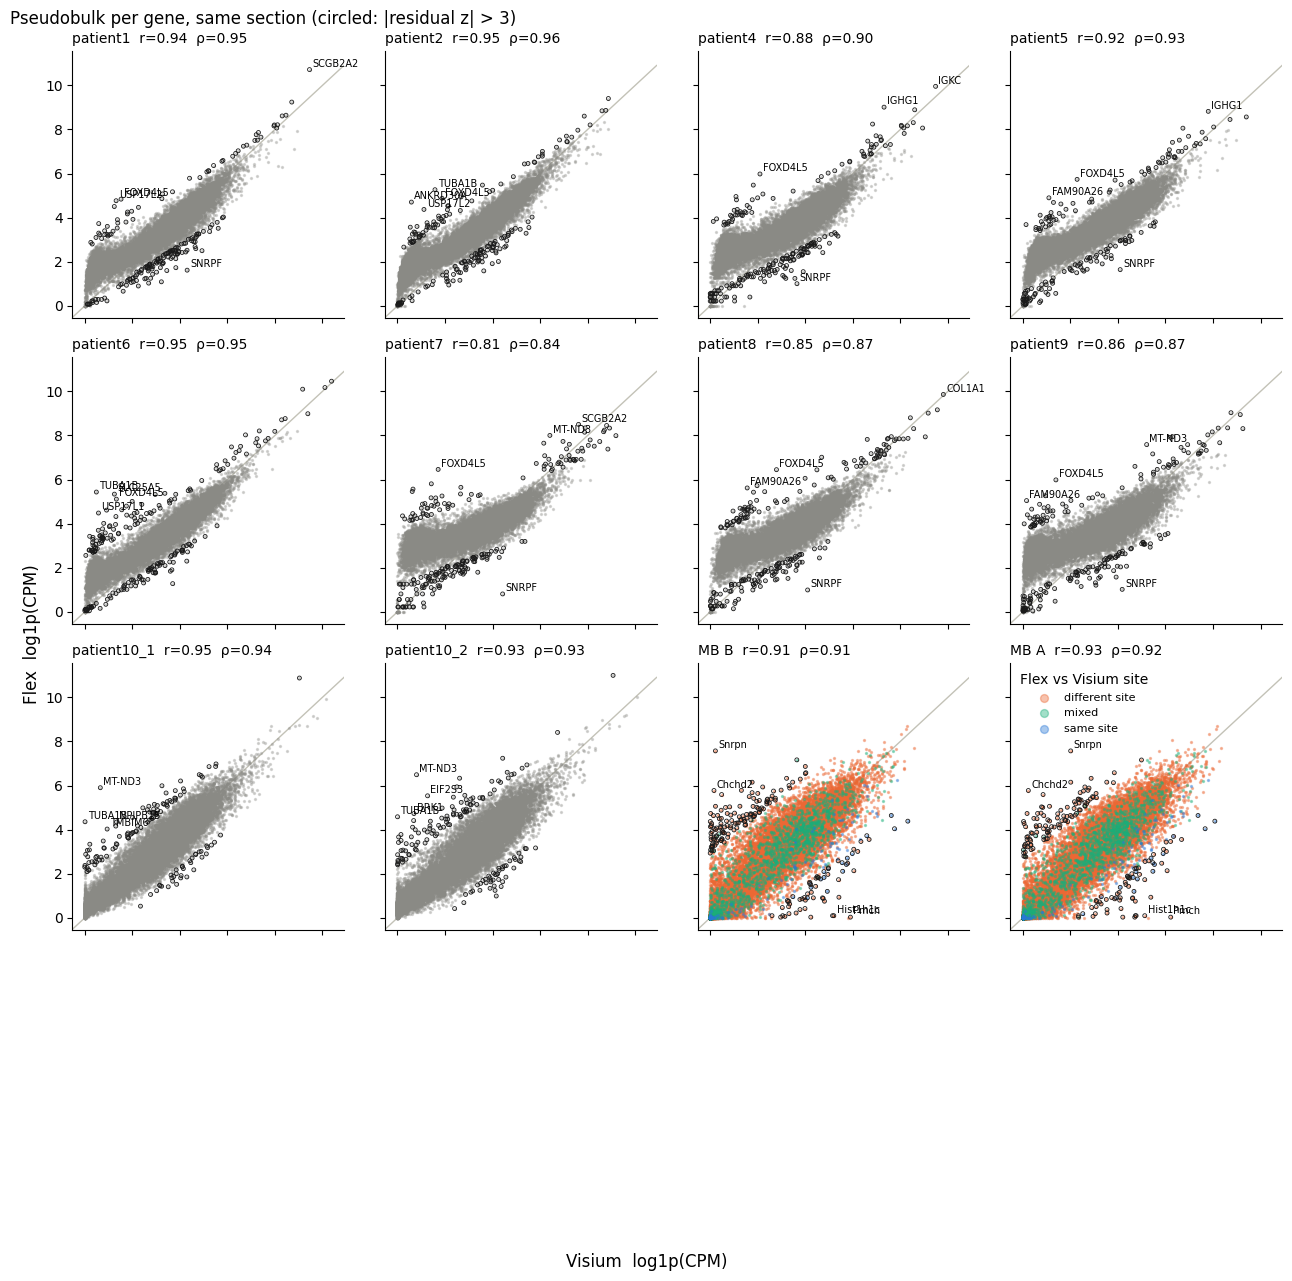

In [10]:
fig, axes = plt.subplots(4, 4, figsize=(13, 13), sharex=True, sharey=True)
for ax, (s, df) in zip(axes.flat, expr.items()):
    if s.startswith("MB"):
        for cat, col in reversed(CAT_COL.items()):  # rare categories on top
            g = df.index.map(category) == cat
            ax.scatter(df.visium[g], df.flex[g], s=2, alpha=0.4, color=col, rasterized=True, label=cat)
    else:
        ax.scatter(df.visium, df.flex, s=2, alpha=0.3, color="#8a8a85", rasterized=True)
    o = res[s][res[s].z.abs() > 3]
    ax.scatter(o.visium, o.flex, s=8, facecolors="none", edgecolors="#1a1a1a", linewidths=0.6)
    for g in o.z.abs().nlargest(4).index:
        ax.annotate(symbol.get(g, g), (o.visium[g], o.flex[g]), fontsize=7, xytext=(2, 2), textcoords="offset points")
    ax.axline((0, 0), slope=1, color="#c3c2b7", lw=1, zorder=0)
    ax.set_title(f"{s}  r={cor.pearson[s]:.2f}  ρ={cor.spearman[s]:.2f}", loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes.flat[len(expr) - 1].legend(title="Flex vs Visium site", markerscale=4, frameon=False, fontsize=8)
for ax in axes.flat[len(expr):]:
    ax.set_visible(False)
fig.supxlabel("Visium  log1p(CPM)")
fig.supylabel("Flex  log1p(CPM)")
fig.suptitle("Pseudobulk per gene, same section (circled: |residual z| > 3)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(OUT_DIR / "visium_flex_gene_scatter.pdf", dpi=300)
plt.show()

Recurrent human outliers: genes flagged in several BC samples point to a systematic Visium vs nuclei difference
(e.g. nuclear-retained vs cytoplasmic transcripts), not to probe-site depletion.

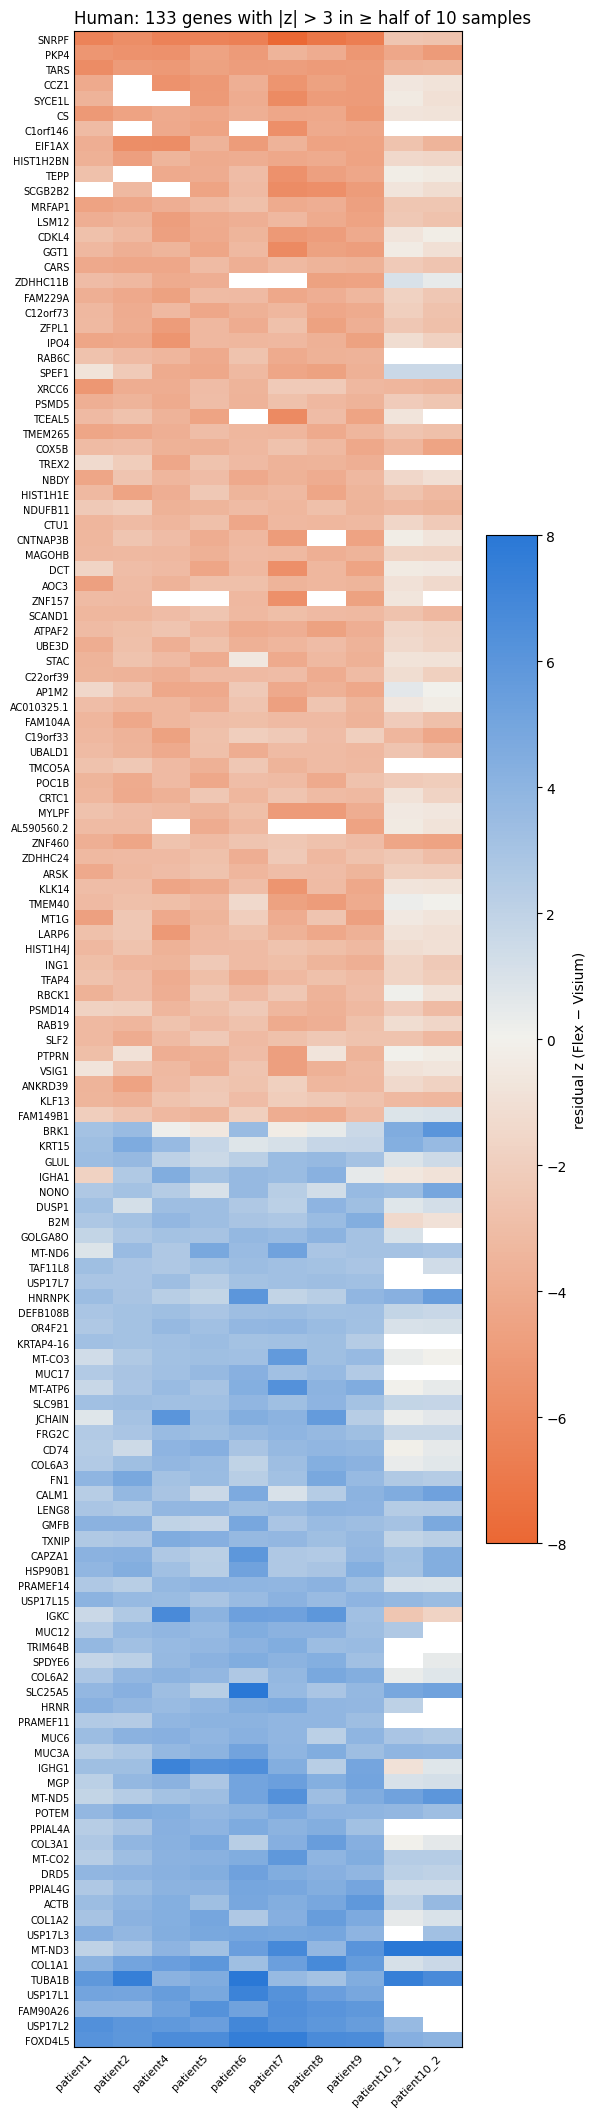

Genes with a DEPRECATED_ Flex probe: median |z| 0.8 vs all genes 0.59
Visium-only human genes (not in comparison): ['GABARAPL2', 'SLC39A4', 'TKT']


In [11]:
z_hum = pd.DataFrame({s: d.z for s, d in res.items() if not s.startswith("MB")})
recurrent = (z_hum.abs() > 3).sum(axis=1).sort_values(ascending=False)
top = z_hum.loc[recurrent.index[recurrent >= z_hum.shape[1] / 2]]
top = top.loc[top.median(axis=1).sort_values().index]
top.set_index(top.index.map(symbol)).assign(n_outlier=recurrent[top.index].values).round(2).to_csv(OUT_DIR / "human_recurrent_outliers.csv")

div = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f2f1ec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(6, max(2, 0.16 * len(top))))
im = ax.imshow(top, cmap=div, vmin=-8, vmax=8, aspect="auto")
ax.set_yticks(range(len(top)), top.index.map(symbol), fontsize=7)
ax.set_xticks(range(top.shape[1]), top.columns, rotation=45, ha="right", fontsize=8)
ax.tick_params(length=0)
fig.colorbar(im, ax=ax, label="residual z (Flex − Visium)", shrink=0.5)
ax.set_title(f"Human: {len(top)} genes with |z| > 3 in ≥ half of {z_hum.shape[1]} samples", loc="left")
fig.tight_layout()
fig.savefig(OUT_DIR / "human_recurrent_outliers_heatmap.pdf")
plt.show()

dep = probes["Chromium Human v1.0.1"].query("probe_id.str.startswith('DEPRECATED_')").gene_id.str.removeprefix("DEPRECATED_")
print("Genes with a DEPRECATED_ Flex probe: median |z|", z_hum[z_hum.index.isin(dep)].abs().median().median().round(2),
      "vs all genes", z_hum.abs().median().median().round(2))
print("Visium-only human genes (not in comparison):", sorted(symbol[list(set(probes["Visium Human v2.0"].query("included").gene_id) - panel["Human"])]))

Mouse depletion test: is Flex signal lower when Flex binds the **same site** Visium used?

More Flex probes give more Flex signal, so genes are compared only within the same probe count (1 vs ≥2 Flex probes).
Almost all same-site genes have a single probe; mixed genes have ≥2 by definition.

MB B {'same site (1)': 'median z -1.61, 18.2% outliers', 'different site (1)': 'median z -0.92, 8.1% outliers', 'same site (≥2)': 'median z -2.04, 0.0% outliers', 'mixed (≥2)': 'median z -0.28, 0.4% outliers', 'different site (≥2)': 'median z -0.07, 1.0% outliers'}
MB A {'same site (1)': 'median z -1.77, 17.2% outliers', 'different site (1)': 'median z -0.92, 9.0% outliers', 'same site (≥2)': 'median z -1.89, 0.0% outliers', 'mixed (≥2)': 'median z -0.22, 0.5% outliers', 'different site (≥2)': 'median z -0.07, 0.8% outliers'}


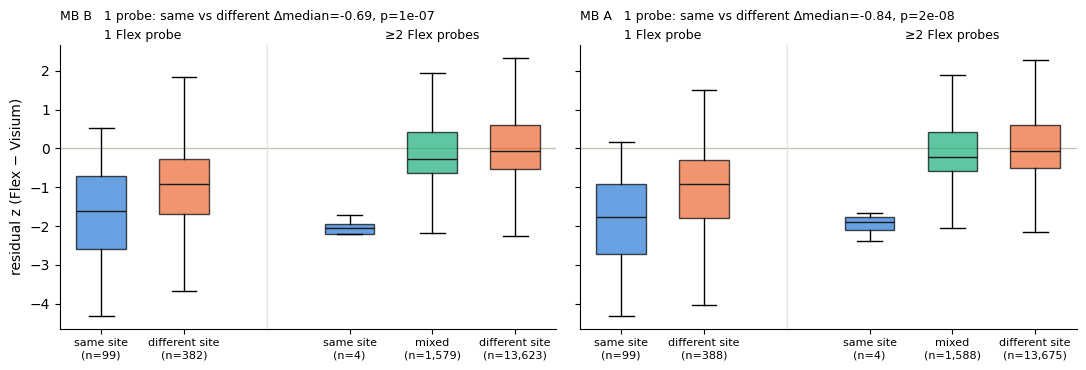

In [12]:
POS = {("same site", "1"): 1, ("different site", "1"): 2,
       ("same site", "≥2"): 4, ("mixed", "≥2"): 5, ("different site", "≥2"): 6}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, s in zip(axes, ["MB B", "MB A"]):
    d = res[s].assign(category=res[s].index.map(category),
                      probes=np.where(res[s].index.map(n_flex) == 1, "1", "≥2"))
    groups = {k: d.z[(d.category == k[0]) & (d.probes == k[1])] for k in POS}
    bp = ax.boxplot(groups.values(), positions=list(POS.values()), widths=0.6, showfliers=False,
                    patch_artist=True, medianprops={"color": "#1a1a1a"},
                    tick_labels=[f"{cat}\n(n={len(g):,})" for (cat, _), g in groups.items()])
    for patch, (cat, _) in zip(bp["boxes"], groups):
        patch.set_facecolor(CAT_COL[cat]); patch.set_alpha(0.7)
    ax.axhline(0, color="#c3c2b7", lw=1, zorder=0)
    ax.axvline(3, color="#e5e4df", lw=1)
    for x, lab in [(1.5, "1 Flex probe"), (5, "≥2 Flex probes")]:
        ax.text(x, 1.02, lab, transform=ax.get_xaxis_transform(), ha="center", fontsize=9)
    same, diff = groups[("same site", "1")], groups[("different site", "1")]
    ax.set_title(f"{s}   1 probe: same vs different Δmedian={same.median() - diff.median():+.2f}, "
                 f"p={stats.mannwhitneyu(same, diff).pvalue:.1g}", loc="left", fontsize=9, pad=18)
    ax.tick_params(axis="x", labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    print(s, {f"{c} ({p})": f"median z {g.median():.2f}, {(g.abs() > 3).mean():.1%} outliers" for (c, p), g in groups.items()})
axes[0].set_ylabel("residual z (Flex − Visium)")
fig.tight_layout()
fig.savefig(OUT_DIR / "mouse_residual_by_category.pdf")
plt.show()

## 8. Summary figure (reviewer)

Single JPG for email: `summary_probe_overlap.jpg`. Cohort panels (b, e, f) average CPM per gene over sections
(human: 10 BC sections; mouse: sections A + B, both vs snRNA `sample_2` from section B).

**Residual z** (sections 7–8). Per sample, on log1p(CPM) of genes detected in both modalities:
1. fit a straight line Flex = a · Visium + b (least squares over all genes);
2. residual = observed Flex − Flex predicted by the line;
3. z = (residual − mean residual) / SD of residuals.

z = 0: the gene sits on the overall Visium–Flex trend. z = −2: it is 2 SDs lower in Flex than its Visium level predicts.
Being relative to the trend, z ignores global yield differences and only shows **gene-specific** deviation.

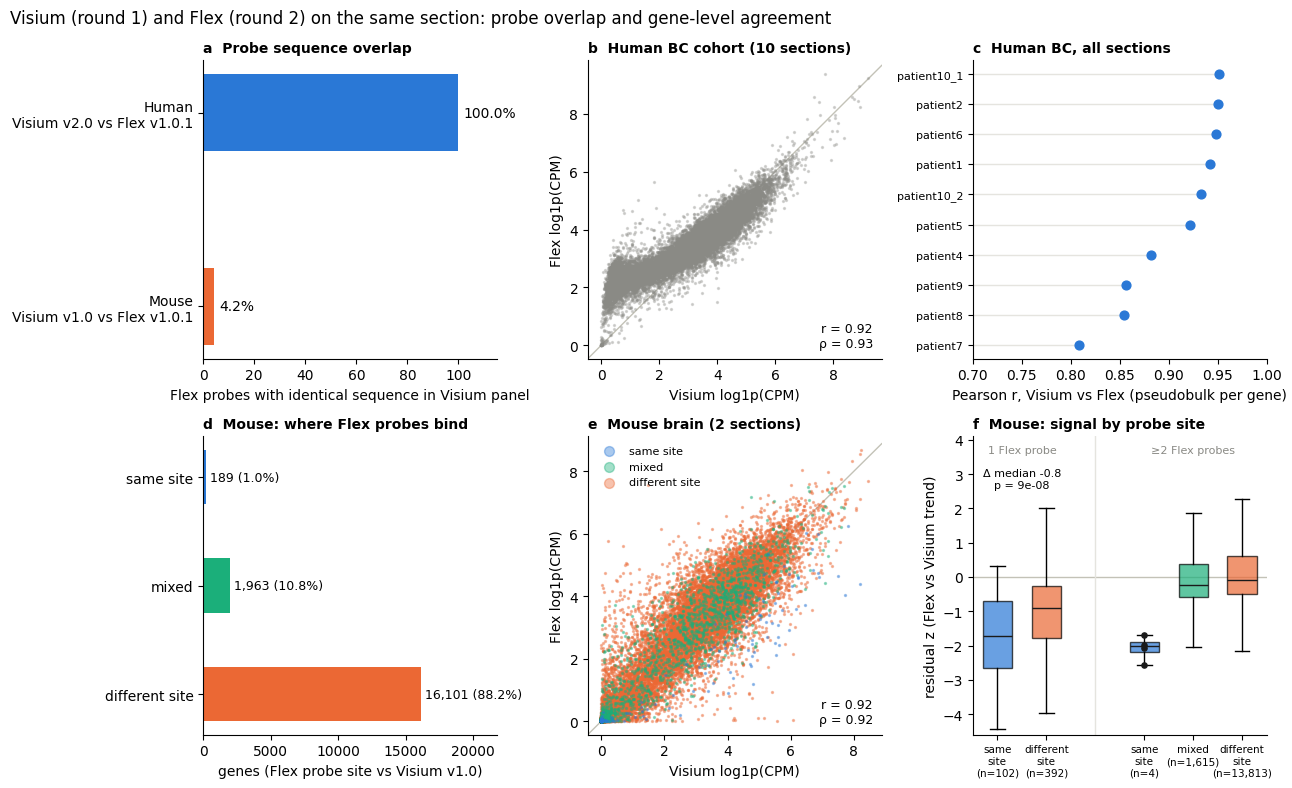

In [13]:
GREY, INK = "#8a8a85", "#1a1a1a"
def clean(ax, title):
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(title, loc="left", fontsize=10, fontweight="bold")

def scatter(ax, s, by_category=False):
    df = expr[s]
    if by_category:
        for cat, col in reversed(CAT_COL.items()):
            g = df.index.map(category) == cat
            ax.scatter(df.visium[g], df.flex[g], s=2, alpha=0.4, color=col, rasterized=True, label=cat)
        h, l = ax.get_legend_handles_labels()
        ax.legend(h[::-1], l[::-1], markerscale=5, frameon=False, fontsize=8, loc="upper left")
    else:
        ax.scatter(df.visium, df.flex, s=2, alpha=0.3, color=GREY, rasterized=True)
    ax.axline((0, 0), slope=1, color="#c3c2b7", lw=1, zorder=0)
    ax.text(0.97, 0.04, f"r = {cor.pearson[s]:.2f}\nρ = {cor.spearman[s]:.2f}", transform=ax.transAxes, ha="right", fontsize=9)
    ax.set_xlabel("Visium log1p(CPM)"); ax.set_ylabel("Flex log1p(CPM)")

fig, ax = plt.subplots(2, 3, figsize=(13, 8))

# a: probe sequence identity
pairs = {"Human\nVisium v2.0 vs Flex v1.0.1": ("Visium Human v2.0", "Chromium Human v1.0.1"),
         "Mouse\nVisium v1.0 vs Flex v1.0.1": ("Visium Mouse v1.0", "Chromium Mouse v1.0.1")}
pct = [100 * probes[f].probe_seq.isin(set(probes[v].probe_seq)).mean() for v, f in pairs.values()]
ax[0, 0].barh(list(pairs), pct, color=["#2a78d6", "#eb6834"], height=0.4)
for y, p in enumerate(pct):
    ax[0, 0].text(p + 2, y, f"{p:.1f}%", va="center", fontsize=10)
ax[0, 0].set_xlim(0, 115); ax[0, 0].invert_yaxis()
ax[0, 0].set_xlabel("Flex probes with identical sequence in Visium panel")
clean(ax[0, 0], "a  Probe sequence overlap")

# b: human cohort, mean CPM per gene over sections
cohort = [s for s in expr if not s.startswith("MB")]
expr["BC cohort"] = np.log1p(sum(np.expm1(expr[s]) for s in cohort) / len(cohort))
df = expr["BC cohort"]
cor.loc["BC cohort", ["pearson", "spearman"]] = stats.pearsonr(df.visium, df.flex)[0], stats.spearmanr(df.visium, df.flex)[0]
scatter(ax[0, 1], "BC cohort")
clean(ax[0, 1], f"b  Human BC cohort ({len(cohort)} sections)")

# c: human r per sample
h = cor.drop(index=["MB A", "MB B", "BC cohort"]).sort_values("pearson")
ax[0, 2].scatter(h.pearson, h.index, color="#2a78d6", s=40, zorder=3)
ax[0, 2].hlines(h.index, 0.7, h.pearson, color="#e5e4df", lw=1)
ax[0, 2].set_xlim(0.7, 1); ax[0, 2].set_xlabel("Pearson r, Visium vs Flex (pseudobulk per gene)")
ax[0, 2].tick_params(axis="y", labelsize=8)
clean(ax[0, 2], "c  Human BC, all sections")

# d: mouse gene categories
n = category.value_counts().reindex(CAT_COL)
ax[1, 0].barh(n.index, n, color=list(CAT_COL.values()), height=0.5)
for y, v in enumerate(n):
    ax[1, 0].text(v + 300, y, f"{v:,} ({100 * v / n.sum():.1f}%)", va="center", fontsize=9)
ax[1, 0].set_xlim(0, n.max() * 1.35); ax[1, 0].invert_yaxis()
ax[1, 0].set_xlabel("genes (Flex probe site vs Visium v1.0)")
clean(ax[1, 0], "d  Mouse: where Flex probes bind")

# e: mouse scatter
# e: mouse, both sections (mean CPM) vs snRNA sample_2
expr["MB"] = np.log1p((np.expm1(expr["MB A"]) + np.expm1(expr["MB B"])) / 2)
res["MB"] = residual_z(expr["MB"])
cor.loc["MB", ["pearson", "spearman"]] = stats.pearsonr(expr["MB"].visium, expr["MB"].flex)[0], stats.spearmanr(expr["MB"].visium, expr["MB"].flex)[0]
scatter(ax[1, 1], "MB", by_category=True)
clean(ax[1, 1], "e  Mouse brain (2 sections)")

# f: mouse residual by category (both sections combined, as in e)
d = res["MB"].assign(category=res["MB"].index.map(category),
                     probes=np.where(res["MB"].index.map(n_flex) == 1, "1", "≥2"))
groups = {k: d.z[(d.category == k[0]) & (d.probes == k[1])] for k in POS}
bp = ax[1, 2].boxplot(groups.values(), positions=list(POS.values()), widths=0.6, showfliers=False, patch_artist=True,
                      medianprops={"color": INK}, tick_labels=[f"{c.replace(' ', chr(10))}\n(n={len(g):,})" for (c, _), g in groups.items()])
for patch, (cat, _) in zip(bp["boxes"], groups):
    patch.set_facecolor(CAT_COL[cat]); patch.set_alpha(0.7)
few = groups[("same site", "≥2")]  # n=4: show the genes
ax[1, 2].scatter(np.full(len(few), POS[("same site", "≥2")]), few, s=14, color=INK, zorder=3)
ax[1, 2].axhline(0, color="#c3c2b7", lw=1, zorder=0); ax[1, 2].axvline(3, color="#e5e4df", lw=1)
for x, lab in [(1.5, "1 Flex probe"), (5, "≥2 Flex probes")]:
    ax[1, 2].text(x, 3.6, lab, ha="center", fontsize=8, color=GREY)
same, diff = groups[("same site", "1")], groups[("different site", "1")]
ax[1, 2].text(1.5, 2.6, f"Δ median {same.median() - diff.median():+.1f}\np = {stats.mannwhitneyu(same, diff).pvalue:.0e}",
              ha="center", fontsize=8)
ax[1, 2].set_ylim(-4.6, 4.1)
ax[1, 2].tick_params(axis="x", labelsize=7.5)
ax[1, 2].set_ylabel("residual z (Flex vs Visium trend)")
clean(ax[1, 2], "f  Mouse: signal by probe site")

fig.suptitle("Visium (round 1) and Flex (round 2) on the same section: probe overlap and gene-level agreement",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(OUT_DIR / "summary_probe_overlap.jpg", dpi=150, pil_kwargs={"quality": 90})
plt.show()

## Findings

**Panels used**
- Human: all BC Visium runs used **Visium Human v2.0**, all Flex runs **Chromium Human v1.0.1**. These are the same panel: 54,580 identical probe sequences. Flex marks 61 probes `DEPRECATED_` and excludes them. Genes measured: 18,082 in both; Visium-only GABARAPL2, SLC39A4, TKT.
- Mouse: MB sections A/B used **Visium Mouse v1.0** (unversioned name in SpaceRanger 2.0.1; all 19,465 matrix genes are in v1.0, 1,113 are absent from v2.0). Flex used Chromium Mouse v1.0.1. Only 2,329 sequences are shared: 4.2% of Flex probes (3.1% of the union of both panels). Of the 18,253 genes in both panels: **88.2% different site**, 10.8% mixed, 1.0% (189) same site.
- Visium Mouse v2.0 and Chromium v1.1.0 have the same sequences as Flex v1.0.1, re-annotated (not used here).

**Visium vs Flex, same section (pseudobulk log1p CPM)**
- Human BC (10 sections, patient3 excluded as in the paper): Pearson r 0.81–0.95 per section. Mouse: 0.91 (B, matched) / 0.93 (A). Correlation is high even though every human Flex probe re-hybridizes to the site used in round 1.
- Recurrent human outliers (|z| > 3 in ≥ half of the samples) look biological / compartmental rather than probe-related. Higher in Flex: mitochondrial transcripts, immunoglobulins / collagens / mucins and some multi-copy families (USP17L, FAM90A, FOXD4L). Lower in Flex: small housekeeping / translation genes (SNRPF, TARS, EIF1AX). Human probes are identical in both rounds, so these are not due to probe design.
- Genes with a deprecated Flex probe: median |z| 0.8 vs 0.59 overall (minor).

**Target-site depletion (mouse)**
- Among genes with 1 Flex probe, **same site** genes have lower Flex signal than **different site** genes: Δ median z −0.7 (B) / −0.8 (A), p ≈ 1e-7. Outlier rate is 18% vs 8%.
- So sites used by Visium are partly depleted for Flex, consistent with RNase H cutting probe-bound copies. They are not lost: these genes are still detected and still correlate with Visium.
- In human, every gene is "same site". Any depletion therefore hits all genes alike: lower total capture, no gene-specific bias.